# Kernels on the Earth

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/kernellib/blob/main/docs/notebooks/geo_kernels.ipynb)

Geographic data live on a sphere of radius $R \approx 6371$ km, not on the $(\text{lon}, \text{lat})$ rectangle they are stored in. Treating longitude and latitude as Euclidean coordinates breaks distances at the dateline and the poles, and the most natural fix, an RBF kernel of the great-circle distance, quietly breaks positive-definiteness. This notebook walks through the whole geo toolbox of kernellib with physical units throughout: distances and neighbours, the positive-definiteness trap, variography and kriging, anisotropy, global-scale regression on $10^5$ satellite observations, sparse tapered covariances, and a tour of space–time, transport, regional, mesh and seasonal kernels. The [Kernels on the Earth guide](../guide/geo.md) is the short reference for the same material.

**What you'll learn:**

1. Why great-circle (or chordal) distance, not lon/lat Euclidean distance, and how `metric="great_circle"` fixes neighbour searches at the dateline and the poles.
2. Why an RBF of the great-circle distance is *not* a valid covariance on $S^2$ (Schoenberg, Gneiting), and three valid alternatives.
3. The geostatistics workflow: empirical semivariogram, a fitted model (nugget, sill, range in km), and kriging with the fitted kernel.
4. Geometric anisotropy as rotated correlation ellipses.
5. How to scale: spherical-harmonic features for $10^5$ points, and covariance tapering with a sparse Cholesky.
6. Bonus: Gneiting space–time, advected plumes, Slepian regional fits, Matérn on meshes, and seasonal cycles with `PeriodicFeatures`.

## Setup

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "kernellib @ git+https://github.com/jejjohnson/kernellib@main",
        ],
        check=True,
    )

In [2]:
import importlib.util
import logging
import math
import time
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

import einx
import gaussx as gx
import jax
import jax.numpy as jnp
import lineax as lx
import matplotlib.pyplot as plt
import numpy as np
from geonnax.basis import fibonacci_sphere, icosphere
from matplotlib.ticker import MaxNLocator
from scipy.spatial import Delaunay

import kernellib as kl


jax.config.update("jax_enable_x64", True)
NOTEBOOK_START = time.perf_counter()

In [3]:
try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic(
        "watermark", "-v -m -p jax,gaussx,geonnax,matplotlib,kernellib"
    )
else:
    print("watermark extension not installed; skipping reproducibility readout.")
if ipython is not None:  # smaller embedded PNGs: same pixels, better compression
    ipython.run_line_magic(
        "config",
        "InlineBackend.print_figure_kwargs = "
        "{'bbox_inches': 'tight', 'pil_kwargs': {'optimize': True}}",
    )

Python implementation: CPython
Python version       : 3.13.14
IPython version      : 9.17.1

jax       : 0.11.2
gaussx    : 0.6.5
geonnax   : 0.0.8
matplotlib: 3.11.2
kernellib : 0.0.19

Compiler    : GCC 13.3.0
OS          : Linux
Release     : 6.18.44-fc-v114
Machine     : x86_64
Processor   : x86_64
CPU cores   : 4
Architecture: 64bit



### Conventions and plotting helpers

Every geo function in kernellib takes `(N, 2)` arrays of **`(lon, lat)`, longitude first**, in degrees by default (`degrees=False` for radians). Distances, lengthscales and ranges are in the units of `radius`: `radius=1.0` (the default) means the unit sphere, so a lengthscale of `0.1` is $0.1$ rad $\approx 637$ km, while `radius=kl.EARTH_RADIUS_KM` puts everything in kilometres. We use kilometres throughout. Variances are in squared field units, here K² for a temperature-like anomaly.

Three unit pitfalls cause most silent bugs:

- **Degrees vs radians.** `(lon, lat)` are read as degrees unless `degrees=False`; passing radians to a degree-default function shrinks every distance by a factor $180/\pi \approx 57$.
- **Unit sphere vs kilometres.** With the default `radius=1.0`, a `lengthscale=500.0` means 500 *radians*, a field that is constant over the globe. Lengthscales, ranges and taper ranges are always in the units of `radius`.
- **`SphereMatern`'s lengthscale.** It is the $\ell$ of the spectrum $(2\nu/\ell^2 + \lambda_l)^{-(\nu+1)}$ with $\lambda_l = l(l+1)/R^2$, so it is in the units of `radius` and, for $\ell \ll R$, matches the Euclidean `Matern` with the same $\nu$ and $\ell$. (The graph Matérn uses the exponent $-\nu$, without the dimension.)

The maps below are plain equirectangular lon/lat plots (no cartopy): fields on a $2° \times 2°$ grid, diverging `RdBu_r` centred at zero for signed anomalies, `viridis` for magnitudes (distances, correlations, standard deviations).

In [4]:
R = kl.EARTH_RADIUS_KM
KM_PER_DEG = math.pi * R / 180.0
print(f"EARTH_RADIUS_KM = {R} km;  1° of arc = {KM_PER_DEG:.1f} km")

EXTENT = (-180.0, 180.0, -90.0, 90.0)
DPI = 58  # keeps the executed notebook small
lon_grid = jnp.linspace(-179.0, 179.0, 180)
lat_grid = jnp.linspace(-89.0, 89.0, 90)
LON, LAT = jnp.meshgrid(lon_grid, lat_grid)
GRID = jnp.stack(
    [einx.id("a b -> (a b)", LON), einx.id("a b -> (a b)", LAT)], axis=-1
)  # (16200, 2) (lon, lat)
N_LAT = lat_grid.shape[0]


def to_map(values):
    """Reshape a field on GRID back to its (lat, lon) image."""
    return einx.id("(a b) -> a b", values, a=N_LAT)


def lonlat_axes(ax, title=None):
    """Equirectangular lon/lat axes with degree ticks."""
    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xticks(np.arange(-180, 181, 60))
    ax.set_yticks(np.arange(-90, 91, 30))
    ax.set_aspect("equal")
    ax.set_xlabel("longitude [°]")
    ax.set_ylabel("latitude [°]")
    if title:
        ax.set_title(title)


def show_field(ax, values, title, cmap="RdBu_r", vmin=None, vmax=None):
    """Filled contours of a GRID field on lon/lat axes."""
    if vmin is None and cmap == "RdBu_r":
        vmax = float(jnp.max(jnp.abs(values)))
        vmin = -vmax
    vmin = float(jnp.min(values)) if vmin is None else vmin
    vmax = float(jnp.max(values)) if vmax is None else vmax
    im = ax.contourf(
        lon_grid,
        lat_grid,
        to_map(values),
        levels=MaxNLocator(nbins=14, symmetric=cmap == "RdBu_r").tick_values(
            vmin, vmax
        ),
        cmap=cmap,
        extend="both",
    )
    lonlat_axes(ax, title)
    return im

EARTH_RADIUS_KM = 6371.0088 km;  1° of arc = 111.2 km


## 1. Distances: great-circle, chordal, and the lon/lat trap

Write a point as a unit vector $u(x) = (\cos\phi\cos\lambda,\ \cos\phi\sin\lambda,\ \sin\phi)$ for longitude $\lambda$ and latitude $\phi$ (`kl.functional.lonlat_to_unit`). Two points are separated by the central angle $\theta = \arccos(u \cdot u') \in [0, \pi]$, and there are two natural distances:

$$d_{\mathrm{gc}}(x, x') = R\,\theta, \qquad d_{\mathrm{ch}}(x, x') = \lVert R u - R u' \rVert = 2R\sin\frac{\theta}{2}.$$

The great-circle distance $d_{\mathrm{gc}}$ is the length of the shortest path along the surface (what a ship or an aircraft flies); the chordal distance $d_{\mathrm{ch}}$ is the straight line *through* the Earth. The identity $d_{\mathrm{ch}} = 2R\sin(\theta/2)$ follows from $\lVert u - u'\rVert^2 = 2 - 2\cos\theta = 4\sin^2(\theta/2)$. It is monotone in $\theta$, so both distances rank neighbours identically, and they agree to second order at short range: $d_{\mathrm{ch}} = d_{\mathrm{gc}}\,(1 - \theta^2/24 + \dots)$, under 0.2 % below $\theta = 10°$ (1100 km). kernellib computes $\theta$ with the haversine formula, which stays accurate for nearby points where $\arccos$ loses digits.

The naive alternative, Euclidean distance on the $(\lambda, \phi)$ numbers scaled by 111.2 km per degree, has two physical defects. A degree of longitude is $111.2\cos\phi$ km, not 111.2 km, so at 80°N it overestimates east–west distances by a factor $1/\cos 80° \approx 5.8$. And longitude wraps: 179°E and 179°W are 222 km apart, not $358° \times 111$ km. The figure shows the distance from a point at (170°E, 55°N), in the Bering Sea, to everywhere else.

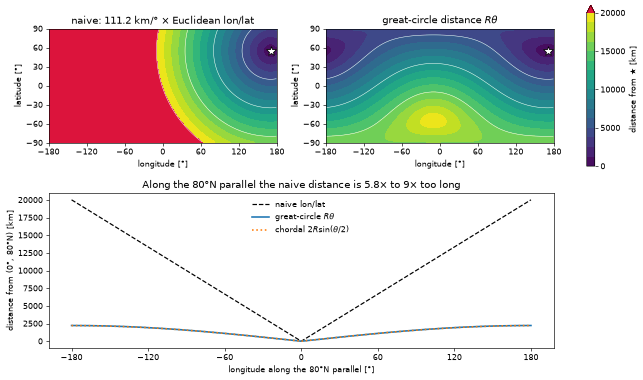

In [5]:
p0 = jnp.array([[170.0, 55.0]])
d_gc = kl.functional.great_circle_distance(p0, GRID, radius=R)[0]
d_naive = KM_PER_DEG * jnp.sqrt(einx.sum("n d -> n", (GRID - p0) ** 2))

lam = jnp.linspace(-180.0, 180.0, 721)
ring = jnp.stack([lam, jnp.full_like(lam, 80.0)], axis=-1)
origin = jnp.array([[0.0, 80.0]])
ring_gc = kl.functional.great_circle_distance(origin, ring, radius=R)[0]
ring_ch = kl.functional.chordal_distance(origin, ring, radius=R)[0]
ring_naive = KM_PER_DEG * jnp.abs(lam)

fig, axd = plt.subplot_mosaic(
    [["naive", "gc"], ["ring", "ring"]],
    figsize=(11, 6.6),
    height_ratios=[1.15, 1],
    constrained_layout=True,
    dpi=DPI,
)
# beyond π R ≈ 20 015 km (antipodal points) a distance is physically impossible
dist_cmap = plt.get_cmap("viridis").with_extremes(over="crimson")
for ax, d, title in [
    (axd["naive"], d_naive, "naive: 111.2 km/° × Euclidean lon/lat"),
    (axd["gc"], d_gc, "great-circle distance $R\\theta$"),
]:
    im = ax.contourf(
        lon_grid,
        lat_grid,
        to_map(d),
        np.arange(0, 20001, 1250),
        cmap=dist_cmap,
        extend="max",
    )
    ax.contour(
        lon_grid,
        lat_grid,
        to_map(d),
        np.arange(0, 20001, 5000),
        colors="w",
        linewidths=0.6,
    )
    lonlat_axes(ax, title)
    ax.plot(*p0[0], marker="*", color="w", ms=13, mec="k")
cbar = fig.colorbar(
    im, ax=[axd["naive"], axd["gc"]], shrink=0.9, label="distance from ★ [km]"
)
cbar.set_ticks(np.arange(0, 20001, 5000))

ax = axd["ring"]
ax.plot(lam, ring_naive, "k--", label="naive lon/lat")
ax.plot(lam, ring_gc, color="C0", lw=2, label="great-circle $R\\theta$")
ax.plot(lam, ring_ch, color="C1", lw=2, ls=":", label="chordal $2R\\sin(\\theta/2)$")
ax.set_xlabel("longitude along the 80°N parallel [°]")
ax.set_ylabel("distance from (0°, 80°N) [km]")
ax.set_title("Along the 80°N parallel the naive distance is 5.8× to 9× too long")
ax.set_xticks(np.arange(-180, 181, 60))
ax.legend(frameon=False)
plt.show()

The naive map has a cliff at the dateline: points a few hundred kilometres east of the star, across 180°, are reported as tens of thousands of kilometres away; everything in crimson is farther than the largest possible distance on the planet, $\pi R \approx 20\,015$ km between antipodes. The great-circle contours wrap smoothly across the dateline and over the pole.

### Neighbours with `metric="great_circle"`

Neighbour searches inherit the same defects. With `metric="great_circle"` (or `"chordal"`), `nearest_neighbors`, `radius_neighbors`, `knn_graph`, `radius_graph` and `estimate_lengthscale` run a Euclidean search on the 3-D unit vectors, which is exact because $d_{\mathrm{ch}}$ is monotone in $\theta$, and report distances in km. Below: the 12 nearest neighbours of a station on the dateline and of one 2° from the North Pole, among 4000 Fibonacci-lattice stations, with the naive lon/lat metric (red) and the great-circle metric (blue). The polar panel uses an azimuthal-equidistant view (radius $= 90° - \phi$).

great-circle distances of the dateline station's neighbours [km]:
[215. 245. 263. 295. 498. 541. 553. 566. 570. 589. 608. 615.]


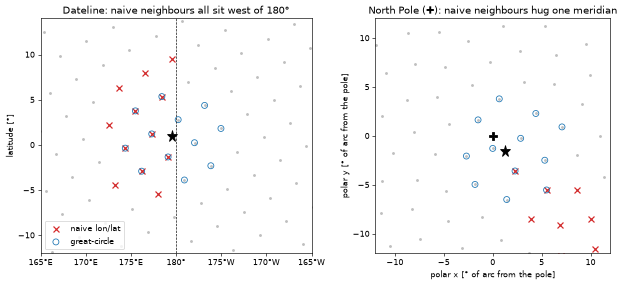

In [6]:
stations, _ = fibonacci_sphere(4000, output="lonlat", output_unit="degrees")
queries = jnp.array([[179.5, 1.0], [40.0, 88.0]])
pts = jnp.concatenate([queries, stations], axis=0)
nn_naive = kl.nearest_neighbors(pts, 12)  # Euclidean on the (lon, lat) numbers
nn_gc = kl.nearest_neighbors(pts, 12, metric="great_circle", radius=R)
print("great-circle distances of the dateline station's neighbours [km]:")
print(np.round(np.asarray(nn_gc.distances[0]), 0))


def polar_xy(lonlat):
    """Azimuthal-equidistant coordinates around the North Pole, in degrees."""
    rho = 90.0 - lonlat[..., 1]
    theta = jnp.radians(lonlat[..., 0])
    return rho * jnp.sin(theta), -rho * jnp.cos(theta)


fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), constrained_layout=True, dpi=DPI)
ax = axes[0]
shift = jnp.mod(pts[:, 0], 360.0)  # 0..360 so the dateline sits mid-panel
ax.scatter(shift, pts[:, 1], s=6, color="0.75")
for nn, color, marker, label in [
    (nn_naive, "C3", "x", "naive lon/lat"),
    (nn_gc, "C0", "o", "great-circle"),
]:
    idx = nn.indices[0]
    ax.scatter(
        shift[idx],
        pts[idx, 1],
        s=55,
        marker=marker,
        color=color,
        facecolors="none" if marker == "o" else None,
        label=label,
    )
ax.plot(shift[0], pts[0, 1], "*", color="k", ms=14)
ax.axvline(180.0, color="k", lw=0.8, ls="--")
ax.set_xlim(165, 195)
ax.set_ylim(-12, 14)
ax.set_aspect("equal")
ax.set_xticks([165, 170, 175, 180, 185, 190, 195])
ax.set_xticklabels(["165°E", "170°E", "175°E", "180°", "175°W", "170°W", "165°W"])
ax.set_ylabel("latitude [°]")
ax.set_title("Dateline: naive neighbours all sit west of 180°")
ax.legend(loc="lower left", frameon=True)

ax = axes[1]
px, py = polar_xy(pts)
ax.scatter(px, py, s=6, color="0.75")
for nn, color, marker in [(nn_naive, "C3", "x"), (nn_gc, "C0", "o")]:
    idx = nn.indices[1]
    ax.scatter(
        px[idx],
        py[idx],
        s=55,
        marker=marker,
        color=color,
        facecolors="none" if marker == "o" else None,
    )
ax.plot(px[1], py[1], "*", color="k", ms=14)
ax.plot(0, 0, "P", color="k", ms=9)
ax.set_xlim(-12, 12)
ax.set_ylim(-12, 12)
ax.set_aspect("equal")
ax.set_xlabel("polar x [° of arc from the pole]")
ax.set_ylabel("polar y [° of arc from the pole]")
ax.set_title("North Pole (✚): naive neighbours hug one meridian")
plt.show()

**Takeaway:** measure distance on the sphere ($R\theta$ or $2R\sin(\theta/2)$), never on the lon/lat rectangle; `metric="great_circle"` makes every neighbour search exact across the dateline and the poles.

## 2. The positive-definiteness trap

A covariance function must be **positive definite**: every Gram matrix $K_{ij} = k(x_i, x_j)$ must have non-negative eigenvalues, otherwise some linear combination $\sum_i c_i Z(x_i)$ of the field gets a negative variance $c^\top K c < 0$. On the sphere, the classical result of Schoenberg {cite:p}`schoenberg1942positive` characterises the isotropic covariances $k(x, x') = \psi(\theta)$: $\psi$ is positive definite on $S^2$ if and only if

$$\psi(\theta) = \sum_{l=0}^{\infty} b_l\, P_l(\cos\theta), \qquad b_l \ge 0,\quad \sum_l b_l < \infty,$$

with $P_l$ the Legendre polynomials and $b_l = \frac{2l+1}{2}\int_{-1}^{1}\psi(\arccos t)\,P_l(t)\,dt$ (`funk_hecke_coefficients(kernel, l_max, convention="legendre")` computes them for any isotropic kernel). The coefficients $b_l$ are the variances carried by the spherical harmonics of degree $l$, the sphere's analogue of a power spectrum, so a negative $b_l$ is a negative variance.

Two consequences, made precise by Gneiting {cite:p}`gneiting2013spheres`:

- **Chordal is always safe.** If $k_0$ is positive definite on $\mathbb{R}^3$, then $k_0(\lVert Ru - Ru'\rVert)$, the same function of the *chordal* distance, is positive definite on the sphere: its Gram is just $k_0$'s Gram at the points $Ru_i \in \mathbb{R}^3$. This is `kl.Chordal(base_kernel, radius=R)`, and it works for every Euclidean kernel and every smoothness.
- **Great-circle needs care.** $\theta$ is not a Euclidean distance, so a Euclidean-valid $\psi$ of $R\theta$ need not satisfy Schoenberg's condition. The Gaussian $e^{-\theta^2/2c^2}$ never does, and the Matérn of $R\theta$ fails for $\nu > \tfrac12$. The exponential ($\nu = \tfrac12$) and the families in Gneiting's Table 1 are valid: `GreatCircleExponential`, `GreatCirclePoweredExponential`, `GreatCircleCauchy`, and the compactly supported `GreatCircleSpherical`, `GreatCircleAskey` and `GreatCircleWendland`.

A third route defines the kernel by its spectrum directly: `SphereMatern` sets $b_l \propto (2l+1)\,(2\nu/\ell^2 + \lambda_l)^{-(\nu+1)}$ with the Laplace–Beltrami eigenvalues $\lambda_l = l(l+1)/R^2$ {cite:p}`borovitskiy2020matern`, which is valid for every $\nu > 0$ by construction.

We test this on 400 near-uniform Fibonacci-lattice points: the smallest Gram eigenvalue $\lambda_{\min}$ of each kernel (unit variance) as the lengthscale $\ell$ grows from 500 km to 12 000 km.

In [7]:
fib, _ = fibonacci_sphere(400, output="lonlat", output_unit="degrees")
D_gc = kl.functional.great_circle_distance(fib, fib, radius=R)  # (400, 400) km
SQRT3 = math.sqrt(3.0)


def kernels_at(ell):
    """Unit-variance Gram matrices of five candidate kernels at lengthscale ell."""
    t = D_gc / ell
    return {
        "RBF of great-circle ✗": jnp.exp(-0.5 * t**2),
        "Matérn-3/2 of great-circle ✗": (1 + SQRT3 * t) * jnp.exp(-SQRT3 * t),
        "Chordal(RBF) ✓": kl.Chordal(kl.RBF(lengthscale=ell), radius=R)(fib, fib),
        "GreatCircleExponential ✓": kl.GreatCircleExponential(
            lengthscale=ell, radius=R
        )(fib, fib),
        "SphereMatern $\\nu$=3/2 ✓": kl.SphereMatern(
            lengthscale=ell, nu=1.5, radius=R, max_degree=128
        )(fib, fib),
    }


ells = np.geomspace(500.0, 12000.0, 14)
min_eig = {}
for ell in ells:
    for name, K in kernels_at(ell).items():
        min_eig.setdefault(name, []).append(float(jnp.linalg.eigvalsh(K)[0]))
for name, vals in min_eig.items():
    print(f"{name:32s} worst λ_min = {min(vals): .2e}")

RBF of great-circle ✗            worst λ_min = -2.87e+00
Matérn-3/2 of great-circle ✗     worst λ_min = -7.98e-02
Chordal(RBF) ✓                   worst λ_min = -4.02e-14
GreatCircleExponential ✓         worst λ_min =  3.91e-02
SphereMatern $\nu$=3/2 ✓         worst λ_min =  1.19e-04


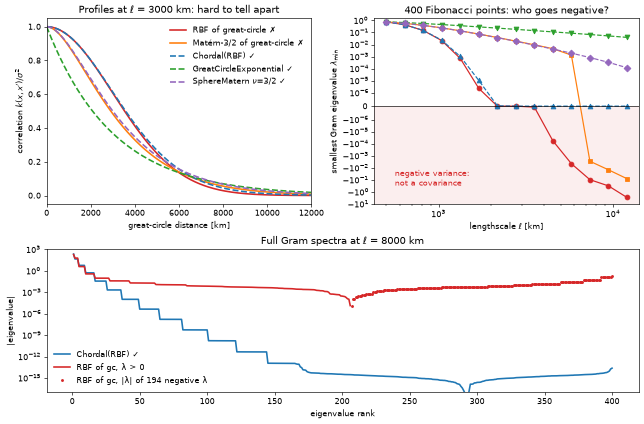

In [8]:
styles = {
    "RBF of great-circle ✗": dict(color="C3", ls="-", marker="o"),
    "Matérn-3/2 of great-circle ✗": dict(color="C1", ls="-", marker="s"),
    "Chordal(RBF) ✓": dict(color="C0", ls="--", marker="^"),
    "GreatCircleExponential ✓": dict(color="C2", ls="--", marker="v"),
    "SphereMatern $\\nu$=3/2 ✓": dict(color="C4", ls="--", marker="D"),
}
ell_show = 3000.0
dist = jnp.linspace(0.0, math.pi * R, 400)
arc = jnp.stack([jnp.zeros_like(dist), 90.0 - dist / KM_PER_DEG], axis=-1)
north = jnp.array([[0.0, 90.0]])
t_arc = dist / ell_show
profiles = {
    "RBF of great-circle ✗": jnp.exp(-0.5 * t_arc**2),
    "Matérn-3/2 of great-circle ✗": (1 + SQRT3 * t_arc) * jnp.exp(-SQRT3 * t_arc),
    "Chordal(RBF) ✓": kl.Chordal(kl.RBF(lengthscale=ell_show), radius=R)(north, arc)[0],
    "GreatCircleExponential ✓": kl.GreatCircleExponential(
        lengthscale=ell_show, radius=R
    )(north, arc)[0],
    "SphereMatern $\\nu$=3/2 ✓": kl.SphereMatern(
        lengthscale=ell_show, nu=1.5, radius=R, max_degree=128
    )(north, arc)[0],
}
spec_bad = jnp.linalg.eigvalsh(kernels_at(8000.0)["RBF of great-circle ✗"])[::-1]
spec_ok = jnp.linalg.eigvalsh(kernels_at(8000.0)["Chordal(RBF) ✓"])[::-1]

fig, axd = plt.subplot_mosaic(
    [["prof", "minev"], ["spec", "spec"]],
    figsize=(11, 7.2),
    height_ratios=[1.3, 1],
    constrained_layout=True,
    dpi=DPI,
)
ax = axd["prof"]
for name, prof in profiles.items():
    st = styles[name]
    ax.plot(dist, prof, color=st["color"], ls=st["ls"], lw=2, label=name)
ax.set_xlabel("great-circle distance [km]")
ax.set_ylabel("correlation $k(x, x') / \\sigma^2$")
ax.set_title(f"Profiles at $\\ell$ = {ell_show:.0f} km: hard to tell apart")
ax.set_xlim(0, 12000)
ax.legend(frameon=False)

ax = axd["minev"]
ax.axhspan(-10.0, -1e-9, color="C3", alpha=0.08)
ax.text(560, -0.3, "negative variance:\nnot a covariance", color="C3")
for name, vals in min_eig.items():
    ax.plot(ells, vals, label=name, **styles[name])
ax.set_xscale("log")
ax.set_yscale("symlog", linthresh=1e-6)
ax.set_ylim(-10.0, 1.5)
ax.axhline(0.0, color="k", lw=0.8)
ax.set_xlabel("lengthscale $\\ell$ [km]")
ax.set_ylabel("smallest Gram eigenvalue $\\lambda_{\\min}$")
ax.set_title("400 Fibonacci points: who goes negative?")

ax = axd["spec"]
rank = np.arange(1, spec_bad.shape[0] + 1)
ax.semilogy(rank, np.abs(spec_ok), color="C0", lw=2, label="Chordal(RBF) ✓")
neg = spec_bad < 0
ax.semilogy(rank[~neg], spec_bad[~neg], color="C3", lw=2, label="RBF of gc, λ > 0")
ax.semilogy(
    rank[neg],
    -spec_bad[neg],
    ".",
    color="C3",
    ms=5,
    label=f"RBF of gc, |λ| of {int(neg.sum())} negative λ",
)
ax.set_ylim(1e-17, 1e3)
ax.set_xlabel("eigenvalue rank")
ax.set_ylabel("|eigenvalue|")
ax.set_title("Full Gram spectra at $\\ell$ = 8000 km")
ax.legend(frameon=False, loc="lower left")
plt.show()

The top-left panel is why the trap is so common: at the same $\ell$ the five correlation profiles look like ordinary, well-behaved decays. Only the spectra tell them apart. Some point configuration breaks an invalid kernel at every $\ell$; on this 400-point lattice the break becomes visible once $\ell$ is a sizeable fraction of the Earth's radius, where the two kernels of the great-circle distance (red, orange) acquire clearly negative eigenvalues (at 8000 km the RBF has 194 of them), far below the $\sim 10^{-14}$ round-off floor that the valid kernels touch when their Grams become numerically low-rank. A GP built on them can report negative predictive variances, and a sampler's Cholesky will fail at random.

**Takeaway:** on the sphere, use a Euclidean kernel of the chordal distance (`Chordal`), a great-circle kernel proven valid (`GreatCircle*`), or a spectral sphere kernel (`SphereMatern`, `SphereHeat`, `SphereSeries`); never an RBF or smooth Matérn of $R\theta$.

## 3. Variography and kriging

The semivariogram {cite:p}`matheron1963principles` measures how dissimilar a field is at lag $h$:

$$\gamma(h) = \tfrac12\,\mathbb{E}\big[(Z(x + h) - Z(x))^2\big] = C(0) - C(h) \quad\text{(second-order stationary } Z\text{)}.$$

With measurement error of variance $\tau^2$ on top of a field with covariance $C(h) = \sigma^2\rho(h)$, the observed semivariogram is $\gamma(h) = \tau^2 + \sigma^2(1 - \rho(h))$ for $h > 0$. Its three landmarks have direct physical readings:

- **nugget** $\tau^2$, the jump at $h \to 0^+$: instrument noise plus variability below the sampling scale [K²];
- **sill** $\tau^2 + \sigma^2$, the plateau: the total variance [K²];
- **range**, the distance at which $\gamma$ reaches (say) 95 % of the sill: the decorrelation length [km]. For a Matérn-3/2 with lengthscale $\ell$ the 95 % range is about $4.74\,\ell/\sqrt3 \approx 2.74\,\ell$.

`empirical_variogram` bins all pairs by distance, here by great-circle distance in km, with Matheron's estimator $\hat\gamma(h_b) = \frac{1}{2N_b}\sum_{(i, j) \in b} (y_i - y_j)^2$ or the outlier-robust Cressie–Hawkins one {cite:p}`cressie1993statistics`; `fit_variogram` then fits $\tau^2$, $\sigma^2$ and $\ell$ by weighted least squares (Cressie's weights $N_b/\gamma(h_b)^2$).

**The synthetic world.** The truth is a draw from a `SphereMatern` field with $\nu = 3/2$ (once mean-square differentiable, like a smooth temperature anomaly), $\ell = 1500$ km and $\sigma^2 = 4$ K², observed at 1500 random stations with noise $\tau^2 = 0.25$ K². We draw it exactly through its spherical-harmonic features (section 5): $f = \Phi w$ with $w \sim \mathcal{N}(0, I)$.

In [9]:
key = jax.random.key(0)
k_lon, k_lat, k_w, k_eps = jax.random.split(key, 4)
truth = kl.SphereMatern(
    lengthscale=1500.0, nu=1.5, variance=4.0, radius=R, max_degree=48
)
print(f"truncation tail at L = 48: {float(truth.truncation_tail()):.1e}")

n_obs = 1500
u = jax.random.uniform(k_lon, (n_obs,))
v = jax.random.uniform(k_lat, (n_obs,))
X_obs = jnp.stack(
    [360.0 * u - 180.0, jnp.degrees(jnp.arcsin(2.0 * v - 1.0))], axis=-1
)  # uniform on the sphere
sh_truth = kl.SphericalHarmonicFeatures().fit(truth, X_obs)
w_true = jax.random.normal(k_w, (sh_truth.n_features,))
f_grid = sh_truth(GRID) @ w_true  # K
tau2_true = 0.25  # K²
y_obs = sh_truth(X_obs) @ w_true + math.sqrt(tau2_true) * jax.random.normal(
    k_eps, (n_obs,)
)

vgm = kl.empirical_variogram(
    X_obs,
    y_obs,
    bins=30,
    max_distance=7000.0,
    estimator="cressie",
    metric="great_circle",
    radius=R,
)
fitted, nugget = kl.fit_variogram(vgm, kl.Matern(nu=1.5))
ell_hat, s2_hat, tau2_hat = (
    float(fitted.lengthscale),
    float(fitted.variance),
    float(nugget),
)
print(f"lengthscale:    fitted {ell_hat:7.0f} km   (truth 1500 km)")
print(f"partial sill σ²: fitted {s2_hat:5.2f} K²   (truth 4.00 K²)")
print(f"nugget τ²:      fitted {tau2_hat:5.2f} K²   (truth 0.25 K²)")

truncation tail at L = 48: 3.3e-03


lengthscale:    fitted    1367 km   (truth 1500 km)
partial sill σ²: fitted  3.68 K²   (truth 4.00 K²)
nugget τ²:      fitted  0.19 K²   (truth 0.25 K²)


The fit is to $\gamma(h)$ in great-circle kilometres with a Euclidean `Matern`, which is fine for *describing* the variogram. For *prediction* we wrap the fitted Matérn in `Chordal`, so the covariance is valid on the sphere while its lengthscale keeps its meaning (chordal ≈ great-circle at the scale of $\ell$). Simple kriging, i.e. the GP posterior mean with the nugget as observation noise, is then

$$\hat Z(x_*) = k_*^\top (K + \tau^2 I)^{-1} y, \qquad \sigma^2_*(x_*) = \sigma^2 - k_*^\top (K + \tau^2 I)^{-1} k_*,$$

computed through `to_operator` and gaussx's cached Cholesky.

In [10]:
k_fit = kl.Chordal(fitted, radius=R)
K_y = kl.to_operator(k_fit, X_obs, noise=tau2_hat)
cache = gx.build_prediction_cache(K_y, y_obs)
K_star = k_fit(GRID, X_obs)  # (16200, 1500)
krig_mean = gx.predict_mean(cache, K_star)
krig_std = jnp.sqrt(gx.predict_variance(cache, K_star, k_fit.diag(GRID)))
rmse = float(jnp.sqrt(jnp.mean((krig_mean - f_grid) ** 2)))
print(
    f"kriging RMSE on the grid: {rmse:.2f} K  (field std {float(f_grid.std()):.2f} K)"
)

kriging RMSE on the grid: 0.45 K  (field std 1.83 K)


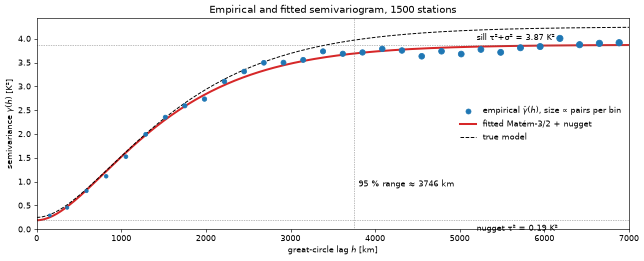

In [11]:
h = vgm.bin_centers
h_fine = jnp.linspace(1.0, 7000.0, 300)
zero = jnp.zeros((1, 1))
gamma_fit = tau2_hat + s2_hat - fitted(einx.id("n -> n 1", h_fine), zero)[:, 0]
gamma_true = (
    tau2_true
    + 4.0
    - kl.Matern(nu=1.5, lengthscale=1500.0, variance=4.0)(
        einx.id("n -> n 1", h_fine), zero
    )[:, 0]
)
practical_range = float(h_fine[jnp.argmax(gamma_fit >= tau2_hat + 0.95 * s2_hat)])

fig, ax = plt.subplots(figsize=(11, 4.4), constrained_layout=True, dpi=DPI)
ax.scatter(
    h,
    vgm.gamma,
    s=12 + 50 * vgm.counts / vgm.counts.max(),
    color="C0",
    zorder=3,
    label="empirical $\\hat\\gamma(h)$, size ∝ pairs per bin",
)
ax.plot(h_fine, gamma_fit, color="C3", lw=2.5, label="fitted Matérn-3/2 + nugget")
ax.plot(h_fine, gamma_true, "k--", lw=1.2, label="true model")
ax.axhline(tau2_hat + s2_hat, color="0.4", lw=0.8, ls=":")
ax.axhline(tau2_hat, color="0.4", lw=0.8, ls=":")
ax.axvline(practical_range, color="0.4", lw=0.8, ls=":")
ax.annotate(
    f"sill τ²+σ² = {tau2_hat + s2_hat:.2f} K²",
    (5200, tau2_hat + s2_hat),
    xytext=(0, 6),
    textcoords="offset points",
)
ax.annotate(
    f"nugget τ² = {tau2_hat:.2f} K²",
    (5200, tau2_hat),
    xytext=(0, -13),
    textcoords="offset points",
)
ax.annotate(
    f"95 % range ≈ {practical_range:.0f} km",
    (practical_range, 0.9),
    xytext=(6, 0),
    textcoords="offset points",
)
ax.set_xlim(0, 7000)
ax.set_ylim(0, None)
ax.set_xlabel("great-circle lag $h$ [km]")
ax.set_ylabel("semivariance $\\gamma(h)$ [K²]")
ax.set_title("Empirical and fitted semivariogram, 1500 stations")
ax.legend(loc="center right", frameon=False)
plt.show()

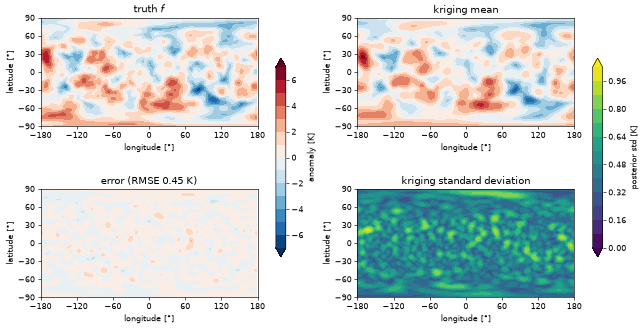

In [12]:
vmax = float(jnp.max(jnp.abs(f_grid)))
fig, axes = plt.subplots(2, 2, figsize=(11, 5.9), constrained_layout=True, dpi=DPI)
im = show_field(axes[0, 0], f_grid, "truth $f$", vmin=-vmax, vmax=vmax)
show_field(axes[0, 1], krig_mean, "kriging mean", vmin=-vmax, vmax=vmax)
show_field(
    axes[1, 0], krig_mean - f_grid, f"error (RMSE {rmse:.2f} K)", vmin=-vmax, vmax=vmax
)
fig.colorbar(im, ax=axes[:, 0], shrink=0.6, label="anomaly [K]")
im_s = show_field(
    axes[1, 1], krig_std, "kriging standard deviation", cmap="viridis", vmin=0.0
)
fig.colorbar(im_s, ax=axes[:, 1], shrink=0.6, label="posterior std [K]")
plt.show()

**Takeaway:** `empirical_variogram(..., metric="great_circle", radius=R)` and `fit_variogram` give nugget, sill and range in physical units in a second; wrap the fitted model in `Chordal` before you krige.

## 4. Anisotropy: rotated correlation ellipses

Real fields rarely decorrelate equally in all directions. Zonal jets and ocean currents stretch structures east–west; valleys and fronts channel them along one bearing. **Geometric anisotropy** keeps a stationary kernel but measures the lag in a rotated, rescaled frame,

$$k(x, x') = k_0\big(A (x - x')\big), \qquad A = \operatorname{diag}\big(1, 1/a\big)\, R_\alpha^\top,$$

so the correlation contours are ellipses whose major axis, at angle $\alpha$ counter-clockwise from east, carries the base lengthscale $\ell$ and whose minor axis carries $a\ell$ ($0 < a \le 1$). `GeometricAnisotropy.from_angles(k0, alpha, a, degrees=True)` builds it, and `LinearTransform(k0, A)` takes any $A$. Because $S_A(\omega) = |\det A|^{-1} S_0(A^{-\top}\omega)$ stays in closed form, random Fourier features still apply, which is how we draw the samples below on a local tangent plane in km (a 2000 km box, a regional model).

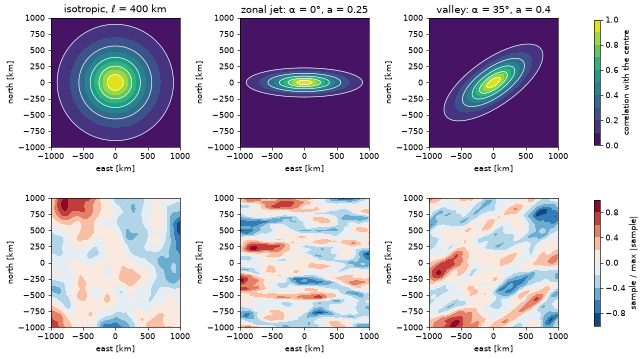

In [13]:
base = kl.Matern(nu=1.5, lengthscale=400.0)  # km
aniso = {
    "isotropic, $\\ell$ = 400 km": base,
    "zonal jet: α = 0°, a = 0.25": kl.GeometricAnisotropy.from_angles(
        base, 0.0, 0.25, degrees=True
    ),
    "valley: α = 35°, a = 0.4": kl.GeometricAnisotropy.from_angles(
        base, 35.0, 0.4, degrees=True
    ),
}
xs = jnp.linspace(-1000.0, 1000.0, 121)
XX, YY = jnp.meshgrid(xs, xs)
plane = jnp.stack(
    [einx.id("a b -> (a b)", XX), einx.id("a b -> (a b)", YY)], axis=-1
)  # km
centre = jnp.zeros((1, 2))
key_rff = jax.random.key(0)

fig, axes = plt.subplots(2, 3, figsize=(11, 6.3), constrained_layout=True, dpi=DPI)
for j, (title, kern) in enumerate(aniso.items()):
    corr = einx.id("(a b) -> a b", kern(plane, centre)[:, 0], a=xs.shape[0])
    ax = axes[0, j]
    im_c = ax.contourf(xs, xs, corr, np.linspace(0, 1, 11), cmap="viridis")
    ax.contour(xs, xs, corr, [0.1, 0.3, 0.5, 0.7, 0.9], colors="w", linewidths=0.8)
    ax.set_title(title)
    rff = kl.RandomFourierFeatures(2000, key_rff).fit(kern, plane)
    Phi_rff = rff(plane)  # (N, 2 × 2000): cos and sin features
    w_rff = jax.random.normal(jax.random.key(1), (Phi_rff.shape[1],))
    sample = einx.id("(a b) -> a b", Phi_rff @ w_rff, a=xs.shape[0])
    lim = float(jnp.max(jnp.abs(sample)))
    im_s = axes[1, j].contourf(
        xs, xs, sample / lim, np.linspace(-1, 1, 11), cmap="RdBu_r"
    )
    for ax in axes[:, j]:
        ax.set_aspect("equal")
        ax.set_xlabel("east [km]")
        ax.set_ylabel("north [km]")
fig.colorbar(im_c, ax=axes[0, :], shrink=0.8, label="correlation with the centre")
fig.colorbar(im_s, ax=axes[1, :], shrink=0.8, label="sample / max |sample|")
plt.show()

**Takeaway:** a rotated range is one wrapper away (`GeometricAnisotropy`), it keeps RFF sampling available, and the correlation ellipse is the picture to check against your field's physics.

## 5. Scale: $10^5$ satellite points and sparse tapered covariances

Dense GP algebra costs $O(N^3)$ time and $O(N^2)$ memory, so $N = 10^5$ is out of reach (80 GB for the Gram alone). Two exact-in-the-limit routes keep the physics and drop the cost.

### 5a. Spherical-harmonic features

Every zonal kernel on the sphere has the Legendre expansion $k(u, v) = \sum_l b_l P_l(u \cdot v)$, and the addition theorem $\sum_{m=-l}^{l} Y_{lm}(u)Y_{lm}(v) = \frac{2l+1}{4\pi}P_l(u\cdot v)$ splits each term into products of real spherical harmonics. Truncating at degree $L$ gives $(L+1)^2$ deterministic features

$$\phi_{lm}(u) = \sqrt{\tfrac{4\pi\, b_l}{2l+1}}\; Y_{lm}(u), \qquad \Phi\Phi^\top = k_L,$$

which `SphericalHarmonicFeatures` builds (for `Chordal` kernels the $b_l$ come from the Funk–Hecke theorem, `funk_hecke_coefficients`). A GP then becomes Bayesian linear regression on $(L+1)^2$ weights: $O(N(L+1)^4)$ to fit instead of $O(N^3)$. A degree $l$ resolves half-wavelengths of about $\pi R / l$, so $L = 32$ resolves $\sim 625$ km, plenty for a field with $\ell = 2000$ km.

The data are 100 000 noisy observations along the ground tracks of a sun-synchronous polar orbiter (inclination 98°, a 100-minute orbit, the Earth turning underneath) over 3 days: dense along track, with gaps between tracks, like real altimetry or sounder data. We accumulate $\Phi^\top\Phi$ and $\Phi^\top y$ in batches of $10^4$ so memory stays at $O(10^4 (L+1)^2)$.

In [14]:
n_sat = 100_000
t_min = jnp.linspace(0.0, 3 * 24 * 60.0, n_sat)  # minutes since start
incl = math.radians(98.0)
arg = 2 * math.pi * t_min / 100.0  # argument of latitude, 100-min orbit
lat_sat = jnp.degrees(jnp.arcsin(math.sin(incl) * jnp.sin(arg)))
lon_inertial = jnp.arctan2(math.cos(incl) * jnp.sin(arg), jnp.cos(arg))
lon_sat = jnp.degrees(lon_inertial - 2 * math.pi * t_min / (24 * 60.0))
X_sat = jnp.stack([jnp.mod(lon_sat + 180.0, 360.0) - 180.0, lat_sat], axis=-1)

field = kl.SphereMatern(
    lengthscale=2000.0, nu=2.5, variance=4.0, radius=R, max_degree=32
)
sh = kl.SphericalHarmonicFeatures().fit(field, X_sat)
n_feat = sh.n_features
noise_sat = 0.3**2  # K²
w_sat = jax.random.normal(jax.random.key(2), (n_feat,))
eps_sat = math.sqrt(noise_sat) * jax.random.normal(jax.random.key(3), (n_sat,))
print(f"{n_sat} points, L = 32 → {n_feat} features, tail {field.truncation_tail():.1e}")


@jax.jit
def batch_stats(Xb, eb):
    """Phi^T Phi and Phi^T y for one batch (the truth uses the same features)."""
    Pb = sh(Xb)
    yb = Pb @ w_sat + eb
    return einx.dot("n f, n g -> f g", Pb, Pb), einx.dot("n f, n -> f", Pb, yb)


tic = time.perf_counter()
PtP = jnp.zeros((n_feat, n_feat))
Pty = jnp.zeros(n_feat)
for i in range(0, n_sat, 10_000):
    a_b, b_b = batch_stats(X_sat[i : i + 10_000], eps_sat[i : i + 10_000])
    PtP, Pty = PtP + a_b, Pty + b_b
precision = lx.MatrixLinearOperator(
    PtP / noise_sat + jnp.eye(n_feat), lx.positive_semidefinite_tag
)  # prior w ~ N(0, I)
w_mean = gx.solve(precision, Pty / noise_sat)
L_post = gx.cholesky(precision).as_matrix()
w_mean.block_until_ready()
fit_seconds = time.perf_counter() - tic

P_grid = sh(GRID)
f_sat_true = P_grid @ w_sat
f_sat_mean = P_grid @ w_mean
V_grid = jax.scipy.linalg.solve_triangular(
    L_post, einx.id("n f -> f n", P_grid), lower=True
)
f_sat_std = jnp.sqrt(einx.sum("f n -> n", V_grid**2))
rmse_sat = float(jnp.sqrt(jnp.mean((f_sat_mean - f_sat_true) ** 2)))
print(f"fit (features + solve) in {fit_seconds:.1f} s;  grid RMSE {rmse_sat:.3f} K")

100000 points, L = 32 → 1089 features, tail 4.4e-04


fit (features + solve) in 4.8 s;  grid RMSE 0.037 K


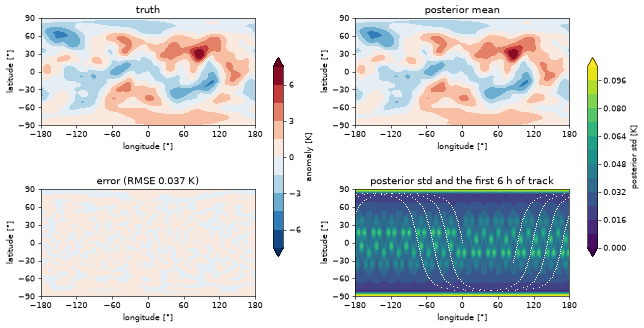

In [15]:
vmax = float(jnp.max(jnp.abs(f_sat_true)))
fig, axes = plt.subplots(2, 2, figsize=(11, 5.9), constrained_layout=True, dpi=DPI)
im = show_field(axes[0, 0], f_sat_true, "truth", vmin=-vmax, vmax=vmax)
show_field(axes[0, 1], f_sat_mean, "posterior mean", vmin=-vmax, vmax=vmax)
show_field(
    axes[1, 0],
    f_sat_mean - f_sat_true,
    f"error (RMSE {rmse_sat:.3f} K)",
    vmin=-vmax,
    vmax=vmax,
)
fig.colorbar(im, ax=axes[:, 0], shrink=0.6, label="anomaly [K]")
im_s = show_field(
    axes[1, 1],
    f_sat_std,
    "posterior std and the first 6 h of track",
    cmap="viridis",
    vmin=0,
)
first = X_sat[: n_sat // 12]  # 6 of the 72 hours
axes[1, 1].plot(first[::20, 0], first[::20, 1], ",", color="w")
fig.colorbar(im_s, ax=axes[:, 1], shrink=0.6, label="posterior std [K]")
plt.show()

The posterior standard deviation is a map of the sampling: tiny where the converging tracks oversample the high latitudes, slightly larger in the diamond-shaped gaps between equatorial crossings, and largest in the two polar caps poleward of 82°, which a 98° orbit never overflies.

### 5b. Covariance tapering with a sparse Cholesky

When the field is rough or $\ell$ is short, $(L+1)^2$ explodes and features stop paying. Tapering {cite:p}`furrer2006tapering` instead multiplies the covariance by a compactly supported, positive-definite taper $T$,

$$K_{\mathrm{tap}} = K \circ T, \qquad T(\theta) = 0 \text{ for } R\theta \ge \rho,$$

which stays positive semidefinite by the Schur product theorem and is exactly zero beyond the taper range $\rho$: about $N\bar m$ non-zeros for $\bar m$ neighbours within $\rho$. On the sphere the taper is `GreatCircleWendland` $\psi(t) = (1 + \tau t)(1 - t)_+^\tau$, valid for $\rho \le \pi R$. The taper should be at least as smooth at the origin as $K$ (Furrer et al., Thm 2.2), and $\rho$ should cover the lags that dominate the kriging weights, a few station spacings and ideally a good fraction of $\ell$; too short a $\rho$ throws away real correlation. `tapered_operator` finds the pattern with a great-circle `radius_neighbors` search and returns a `gaussx.SparseOperator`, which `gaussx.SparseCholeskySolver` factorises with a fill-reducing ordering.

Below: 10 000 stations, a `GreatCircleExponential` covariance with $\ell = 800$ km, a 600 km Wendland taper and a nugget, compared against the dense Cholesky of the same matrix.

In [16]:
n_tap = 10_000
X_tap, _ = fibonacci_sphere(n_tap, output="lonlat", output_unit="degrees")
cov = kl.GreatCircleExponential(lengthscale=800.0, variance=4.0, radius=R)
taper_km = 600.0
tic = time.perf_counter()
K_tap = kl.tapered_operator(
    cov, X_tap, taper_range=taper_km, metric="great_circle", radius=R, max_neighbors=128
)
K_tap = K_tap.add_diagonal(jnp.full(n_tap, 0.25))
t_build = time.perf_counter() - tic
solver = gx.SparseCholeskySolver()

tic = time.perf_counter()
logdet_sparse = solver.logdet(K_tap).block_until_ready()
t_first = time.perf_counter() - tic
K_tap2 = kl.tapered_operator(
    kl.GreatCircleExponential(lengthscale=900.0, variance=4.0, radius=R),
    X_tap,
    taper_range=taper_km,
    metric="great_circle",
    radius=R,
    pattern=K_tap.pattern,
).add_diagonal(jnp.full(n_tap, 0.25))  # new hyperparameters, same pattern
tic = time.perf_counter()
solver.logdet(K_tap2).block_until_ready()
t_refactor = time.perf_counter() - tic

K_dense = K_tap.as_matrix()
tic = time.perf_counter()
logdet_dense = jnp.linalg.slogdet(K_dense)[1].block_until_ready()
t_dense = time.perf_counter() - tic
density = float(jnp.mean(K_dense != 0))
print(f"non-zeros: {100 * density:.2f} % of the {n_tap}² entries")
print(f"log-det sparse {float(logdet_sparse):.6f} vs dense {float(logdet_dense):.6f}")
print(f"pattern search + values: {t_build:.1f} s")
print(f"sparse Cholesky, first call (symbolic analysis + JIT): {t_first:.2f} s")
print(f"sparse Cholesky, new hyperparameters, cached pattern: {t_refactor:.2f} s")
print(f"dense Cholesky of the same matrix: {t_dense:.2f} s")

non-zeros: 0.22 % of the 10000² entries
log-det sparse 12935.083711 vs dense 12935.083711
pattern search + values: 5.7 s
sparse Cholesky, first call (symbolic analysis + JIT): 3.26 s
sparse Cholesky, new hyperparameters, cached pattern: 0.41 s
dense Cholesky of the same matrix: 5.14 s


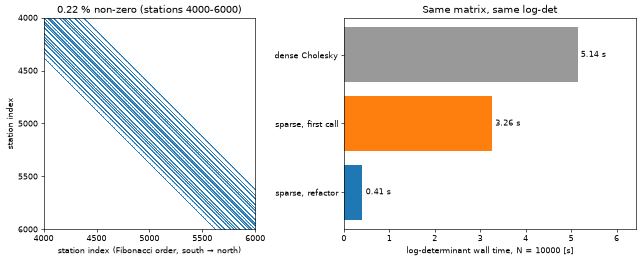

In [17]:
rows, cols = np.nonzero(np.asarray(K_dense[4000:6000, 4000:6000]))
fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 4.4),
    constrained_layout=True,
    dpi=DPI,
    gridspec_kw={"width_ratios": [1, 1.25]},
)
ax = axes[0]
ax.scatter(cols, rows, s=0.05, color="C0", rasterized=True)
ax.set_xlim(0, 2000)
ax.set_ylim(2000, 0)
ax.set_aspect("equal")
ax.set_xlabel("station index (Fibonacci order, south → north)")
ax.set_xticks([0, 500, 1000, 1500, 2000], [4000, 4500, 5000, 5500, 6000])
ax.set_yticks([0, 500, 1000, 1500, 2000], [4000, 4500, 5000, 5500, 6000])
ax.set_ylabel("station index")
ax.set_title(f"{100 * density:.2f} % non-zero (stations 4000-6000)")
ax = axes[1]
labels = ["dense Cholesky", "sparse, first call", "sparse, refactor"]
times = [t_dense, t_first, t_refactor]
bars = ax.barh(labels, times, color=["0.6", "C1", "C0"])
ax.bar_label(bars, fmt="%.2f s", padding=4)
ax.set_xlabel(f"log-determinant wall time, N = {n_tap} [s]")
ax.set_xlim(0, 1.25 * max(times))
ax.invert_yaxis()
ax.set_title("Same matrix, same log-det")
plt.show()

The first sparse call pays for the symbolic analysis and compilation once; every later hyperparameter value reuses the cached pattern (`pattern=`), which is the regime of a likelihood optimisation or an MCMC run, and grows far more slowly than the dense $O(N^3)$ for a fixed taper range: the factor of a 2-D neighbourhood pattern has $O(N\log N)$ to $O(N^{1.5})$ fill under a good ordering.

**Takeaway:** for smooth global fields use `SphericalHarmonicFeatures` (cost set by $L$, not $N$); for rough or short-range fields use `tapered_operator` + `gaussx.SparseCholeskySolver` (cost set by the neighbours within $\rho$).

## 6. Bonus tour

### 6a. Space–time: non-separable Gneiting

The simplest space–time model is separable, $C(h, u) = C_s(h)\,C_t(u)$: the spatial correlation pattern is the same at every time lag. Physically that is rarely true. Large structures (synoptic systems) persist longer than small ones (convective cells), so spatial and temporal scales interact. Gneiting's family {cite:p}`gneiting2002nonseparable` builds that in,

$$C(h, u) = \frac{\sigma^2}{\psi(u)^{\tau}} \exp\!\left(-\frac{c\,\lVert h\rVert^{2\gamma}}{\psi(u)^{\beta\gamma}}\right), \qquad \psi(u) = a|u|^{2\alpha} + 1,$$

with $c = \ell_s^{-2\gamma}$, $a = \ell_t^{-2\alpha}$ and separability $\beta \in [0, 1]$: $\beta = 0$ is separable, and as $\beta \to 1$ the effective spatial range $\ell_s\psi(u)^{\beta/2}$ grows with the time lag. `kl.Gneiting(space_dims=2, ...)` takes `[x, y, t]` inputs; for global data use `space_dims=3` on `R * lonlat_to_unit(X)` (chordal, so it stays valid).

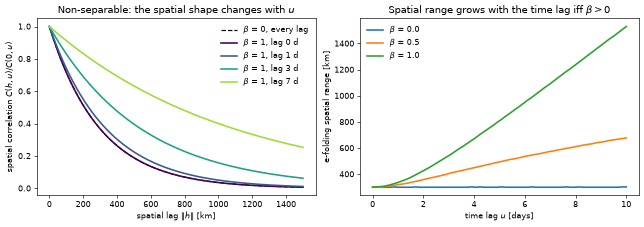

In [18]:
h_km = jnp.linspace(0.0, 1500.0, 200)
lags = [0.0, 1.0, 3.0, 7.0]  # days


def spatial_profile(kernel, h, lag):
    """C(h, u) / C(0, u) along the x-axis at time lag u."""
    pts_st = jnp.stack([h, jnp.zeros_like(h), jnp.full_like(h, lag)], axis=-1)
    c = kernel(pts_st, jnp.zeros((1, 3)))[:, 0]
    return c / c[0]


fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True, dpi=DPI)
ax = axes[0]
gn_sep = kl.Gneiting(
    space_dims=2, space_lengthscale=300.0, time_lengthscale=2.0, beta=0.0
)
gn_full = kl.Gneiting(
    space_dims=2, space_lengthscale=300.0, time_lengthscale=2.0, beta=1.0
)
ax.plot(
    h_km,
    spatial_profile(gn_sep, h_km, 0.0),
    "k--",
    lw=1.5,
    label="$\\beta$ = 0, every lag",
)
for j, lag in enumerate(lags):
    ax.plot(
        h_km,
        spatial_profile(gn_full, h_km, lag),
        lw=2,
        color=plt.cm.viridis(j / 3.5),
        label=f"$\\beta$ = 1, lag {lag:.0f} d",
    )
ax.set_xlabel("spatial lag $\\|h\\|$ [km]")
ax.set_ylabel("spatial correlation $C(h, u) / C(0, u)$")
ax.set_title("Non-separable: the spatial shape changes with $u$")
ax.legend(frameon=False)
u_days = jnp.linspace(0.0, 10.0, 60)
h_long = jnp.linspace(0.0, 5000.0, 2001)
for j, beta in enumerate([0.0, 0.5, 1.0]):
    gn = kl.Gneiting(
        space_dims=2, space_lengthscale=300.0, time_lengthscale=2.0, beta=beta
    )
    eff = [
        float(h_long[jnp.argmax(spatial_profile(gn, h_long, lag) < math.exp(-1))])
        for lag in u_days
    ]
    axes[1].plot(u_days, eff, lw=2, color=f"C{j}", label=f"$\\beta$ = {beta}")
axes[1].set_xlabel("time lag $u$ [days]")
axes[1].set_ylabel("e-folding spatial range [km]")
axes[1].set_title("Spatial range grows with the time lag iff $\\beta > 0$")
axes[1].legend(frameon=False)
plt.show()

**Takeaway:** $\beta$ is a single, learnable number that says how much large spatial scales outlive small ones.

### 6b. Transport: a plume carried by the wind

A tracer released into a steady wind $v$ (a methane plume, smoke) is, to first order, a spatial pattern carried along unchanged, Taylor's frozen-turbulence hypothesis {cite:p}`taylor1938spectrum`: $Z(x, t) = Z_0(x - vt)$. Its covariance is

$$k\big((x, t), (x', t')\big) = k_s(h - v u), \qquad h = x - x',\ u = t - t',$$

`kl.Advected(k_s, v)`, valid for any stationary $k_s$. Pure transport never forgets, so we multiply by an exponential in time for decay. When the wind itself is uncertain, $V \sim \mathcal{N}(\mu, \Sigma_V)$, averaging the frozen-field RBF over it gives the closed form {cite:p}`cox1988simple`

$$C(h, u) = \sigma^2 \big|I + u^2\Sigma_V/\ell^2\big|^{-1/2} \exp\!\Big(-\tfrac12 (h - \mu u)^\top(\ell^2 I + u^2\Sigma_V)^{-1}(h - \mu u)\Big),$$

`kl.RandomAdvectionRBF`: the correlation still travels with the mean wind but spreads and weakens with the lag. Below: the correlation between a sensor at the origin at $t = 0$ and every point of the plane at later times, with a 10 km/h westerly wind (blowing towards the east), $\ell = 4$ km, and a wind uncertainty of 2 km/h per component. Units: km and hours, so velocities are km/h.

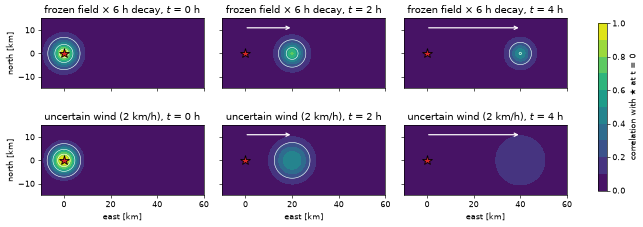

In [19]:
wind = jnp.array([10.0, 0.0])  # km/h, blowing towards the east
frozen = kl.Advected(kl.Matern(nu=1.5, lengthscale=4.0), wind)
decaying = frozen * kl.Matern(nu=0.5, lengthscale=6.0).select((2,))  # 6 h memory
uncertain = kl.RandomAdvectionRBF(wind, 2.0 * jnp.eye(2), lengthscale=4.0)
gx_km = jnp.linspace(-10.0, 60.0, 141)
gy_km = jnp.linspace(-15.0, 15.0, 61)
GX, GY = jnp.meshgrid(gx_km, gy_km)
plane_xy = jnp.stack(
    [einx.id("a b -> (a b)", GX), einx.id("a b -> (a b)", GY)], axis=-1
)
sensor = jnp.zeros((1, 3))
times_h = [0.0, 2.0, 4.0]

fig, axes = plt.subplots(
    2, 3, figsize=(11, 3.9), constrained_layout=True, dpi=DPI, sharex=True, sharey=True
)
for i, (name, kern) in enumerate(
    [("frozen field × 6 h decay", decaying), ("uncertain wind (2 km/h)", uncertain)]
):
    for j, t_h in enumerate(times_h):
        pts_t = jnp.concatenate(
            [plane_xy, jnp.full((plane_xy.shape[0], 1), t_h)], axis=-1
        )
        corr = einx.id("(a b) -> a b", kern(pts_t, sensor)[:, 0], a=gy_km.shape[0])
        ax = axes[i, j]
        im = ax.contourf(gx_km, gy_km, corr, np.linspace(0, 1, 11), cmap="viridis")
        ax.set_aspect("equal")
        ax.contour(gx_km, gy_km, corr, [0.2, 0.5, 0.8], colors="w", linewidths=0.7)
        ax.plot(0, 0, "*", color="C3", ms=12, mec="k")
        if t_h > 0:
            ax.annotate(
                "",
                xy=(10 * t_h, 11),
                xytext=(0, 11),
                arrowprops=dict(arrowstyle="->", color="w", lw=1.5),
            )
        ax.set_title(f"{name}, $t$ = {t_h:.0f} h")
        if i == 1:
            ax.set_xlabel("east [km]")
        if j == 0:
            ax.set_ylabel("north [km]")
fig.colorbar(im, ax=axes, shrink=0.8, label="correlation with ★ at t = 0")
plt.show()

**Takeaway:** `Advected` moves the correlation with the wind (arrow = $v t$); `RandomAdvectionRBF` also smears it as the wind uncertainty accumulates.

### 6c. Regional data: Slepian features over Europe

Global harmonics waste most of their $(L+1)^2$ degrees of freedom outside a region of interest. The Slepian functions of a spherical cap {cite:p}`simons2006slepian` are the band-limited (degree $\le L$) combinations of harmonics that maximise the fraction of their energy inside the cap; about the Shannon number $N_S \approx (L+1)^2 (1 - \cos r)/2$ of them are well concentrated, for cap radius $r$. `SlepianFeatures` projects a zonal kernel onto them: here a `Chordal` Matérn-5/2 with $\ell = 1000$ km over a 25° (2780 km) cap centred on (15°E, 50°N).

In [20]:
cap_centre = (15.0, 50.0)
cap_rad = math.radians(25.0)
k_reg = kl.Chordal(kl.Matern(nu=2.5, lengthscale=1000.0, variance=4.0), radius=R)
sh_reg = kl.SphericalHarmonicFeatures(max_degree=40).fit(k_reg, X_obs)
w_reg = jax.random.normal(jax.random.key(4), (sh_reg.n_features,))

n_reg = 300
k_a, k_b, k_c = jax.random.split(jax.random.key(5), 3)
ang = cap_rad * jnp.sqrt(jax.random.uniform(k_a, (n_reg * 3,)))
bearing = 2 * math.pi * jax.random.uniform(k_b, (n_reg * 3,))
cand = jnp.stack(
    [
        cap_centre[0]
        + jnp.degrees(ang) * jnp.sin(bearing) / math.cos(math.radians(50)),
        cap_centre[1] + jnp.degrees(ang) * jnp.cos(bearing),
    ],
    axis=-1,
)
inside = kl.functional.great_circle_distance(cand, jnp.array([cap_centre]))[:, 0]
X_reg = cand[inside < 0.9 * cap_rad][:n_reg]
y_reg = sh_reg(X_reg) @ w_reg + 0.3 * jax.random.normal(k_c, (X_reg.shape[0],))

sf = kl.SlepianFeatures(l_max=24, cap_radius=cap_rad, cap_centre=cap_centre)
sf = sf.fit(k_reg, X_reg)

rlon = jnp.linspace(-35.0, 65.0, 101)
rlat = jnp.linspace(20.0, 80.0, 61)
RLON, RLAT = jnp.meshgrid(rlon, rlat)
REG = jnp.stack([einx.id("a b -> (a b)", RLON), einx.id("a b -> (a b)", RLAT)], -1)


def chunked(feature_map, X, chunk=40):
    """Evaluate a feature map in fixed-size chunks: one small XLA program."""
    n = X.shape[0]
    pad = jnp.concatenate([X, jnp.repeat(X[:1], -n % chunk, axis=0)], axis=0)
    out = jax.lax.map(feature_map, einx.id("(b c) d -> b c d", pad, c=chunk))
    return einx.id("b c k -> (b c) k", out)[:n]


P_all = chunked(sf, jnp.concatenate([X_reg, REG], axis=0))
P_reg, P_grid_reg = P_all[: X_reg.shape[0]], P_all[X_reg.shape[0] :]
print(
    f"{X_reg.shape[0]} stations, {P_reg.shape[1]} Slepian features "
    f"(Shannon number {float(sf.shannon_number):.1f}) vs {25**2} global harmonics"
)
prec_reg = lx.MatrixLinearOperator(
    einx.dot("n f, n g -> f g", P_reg, P_reg) / 0.09 + jnp.eye(P_reg.shape[1]),
    lx.positive_semidefinite_tag,
)
w_slep = gx.solve(prec_reg, einx.dot("n f, n -> f", P_reg, y_reg) / 0.09)

in_cap = kl.functional.great_circle_distance(REG, jnp.array([cap_centre]))[:, 0]
mask = einx.id("(a b) -> a b", in_cap < cap_rad, a=rlat.shape[0])
f_reg = einx.id("(a b) -> a b", sh_reg(REG) @ w_reg, a=rlat.shape[0])
f_slep = einx.id("(a b) -> a b", P_grid_reg @ w_slep, a=rlat.shape[0])
P_show = einx.id("(a b) f -> f a b", P_grid_reg, a=rlat.shape[0])
rmse_reg = float(jnp.sqrt(jnp.mean((f_slep - f_reg)[mask] ** 2)))
std_reg = float(f_reg[mask].std())
print(f"RMSE inside the cap: {rmse_reg:.2f} K (field std {std_reg:.2f} K)")

300 stations, 29 Slepian features (Shannon number 29.0) vs 625 global harmonics


RMSE inside the cap: 0.44 K (field std 2.03 K)


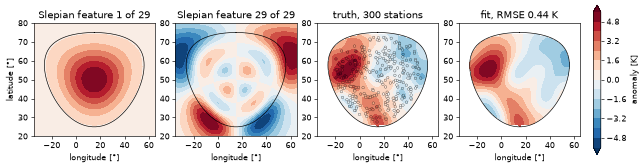

In [21]:
lat0 = math.radians(cap_centre[1])
ring_b = jnp.linspace(0, 2 * math.pi, 200)
ring_lat = jnp.arcsin(
    math.sin(lat0) * math.cos(cap_rad)
    + math.cos(lat0) * math.sin(cap_rad) * jnp.cos(ring_b)
)
ring_lon = cap_centre[0] + jnp.degrees(
    jnp.arctan2(
        jnp.sin(ring_b) * math.sin(cap_rad) * math.cos(lat0),
        math.cos(cap_rad) - math.sin(lat0) * jnp.sin(ring_lat),
    )
)
ring_lat = jnp.degrees(ring_lat)
aspect_reg = 1 / math.cos(lat0)  # local km-true aspect at 50°N
vmax = float(jnp.max(jnp.abs(f_reg[mask])))
lev = MaxNLocator(nbins=14, symmetric=True).tick_values(-vmax, vmax)


def inside_only(F):
    """Mask a regional field outside the cap."""
    return jnp.where(mask, F, jnp.nan)


fig, axes = plt.subplots(1, 4, figsize=(11, 3.3), constrained_layout=True, dpi=DPI)
for ax, idx in zip(axes[:2], [0, P_show.shape[0] - 1], strict=True):
    lim = float(jnp.max(jnp.abs(P_show[idx])))
    ax.contourf(rlon, rlat, P_show[idx], np.linspace(-lim, lim, 15), cmap="RdBu_r")
    ax.set_title(f"Slepian feature {idx + 1} of {P_show.shape[0]}")
im = axes[2].contourf(rlon, rlat, inside_only(f_reg), lev, cmap="RdBu_r", extend="both")
axes[2].scatter(
    X_reg[:, 0],
    X_reg[:, 1],
    c=y_reg,
    cmap="RdBu_r",
    s=10,
    vmin=-vmax,
    vmax=vmax,
    edgecolors="k",
    linewidths=0.3,
)
axes[2].set_title(f"truth, {X_reg.shape[0]} stations")
axes[3].contourf(rlon, rlat, inside_only(f_slep), lev, cmap="RdBu_r", extend="both")
axes[3].set_title(f"fit, RMSE {rmse_reg:.2f} K")
for ax in axes:
    ax.plot(ring_lon, ring_lat, color="k", lw=0.8)
    ax.set_xlim(-35, 65)
    ax.set_ylim(20, 80)
    ax.set_aspect(aspect_reg)
    ax.set_xlabel("longitude [°]")
axes[0].set_ylabel("latitude [°]")
fig.colorbar(im, ax=axes[2:], shrink=0.8, label="anomaly [K]")
plt.show()

**Takeaway:** for a region, `SlepianFeatures` needs only about the Shannon number of features, a small fraction of the $(L+1)^2$ global harmonics, and is accurate inside the cap (do not use it outside, where the features decay).

### 6d. Matérn on meshes: an icosphere and a peninsula

The Matérn field is the solution of the SPDE {cite:p}`lindgren2011spde`

$$\Big(\frac{2\nu}{\ell^2} - \Delta\Big)^{\nu/2 + d/4} f = \mathcal{W},$$

which makes sense on any domain with a Laplacian. `MeshMatern` discretises $\Delta$ with P1 finite elements on a triangle mesh (stiffness $G$, lumped mass $C$), solves $G\varphi = \lambda C\varphi$ once, and sums $\Phi(\lambda_j)\varphi_j(v)\varphi_j(w)$ with $\Phi(\lambda) = (2\nu/\ell^2 + \lambda)^{-(\nu+1)}$ {cite:p}`borovitskiy2020matern`. On an icosphere of radius $R$ the FEM eigenvalues approach $l(l+1)/R^2$, so `MeshMatern` approaches `SphereMatern`; on a domain with a coastline the FEM's natural (Neumann) boundary means correlation flows *around* land, not across it. `MeshLaplaceFeatures` turns the expansion into features, so samples are one matrix product.

In [22]:
V_ico, T_ico = icosphere(4, radius=R)  # 2562 vertices, lengths in km
mesh_k = kl.MeshMatern(V_ico, T_ico, lengthscale=1500.0, nu=1.5, n_components=300)
vid = einx.id("n -> n 1", jnp.arange(V_ico.shape[0]))
mlf = kl.MeshLaplaceFeatures().fit(mesh_k, vid)
sample_ico = mlf(vid) @ jax.random.normal(jax.random.key(6), (mlf.n_features,))
U_ico = V_ico / R
lon_ico = jnp.degrees(jnp.arctan2(U_ico[:, 1], U_ico[:, 0]))
lat_ico = jnp.degrees(jnp.arcsin(U_ico[:, 2]))

h_bay = 2.0  # km mesh spacing
grid_pts = np.array(
    [(x, y) for x in np.arange(0, 100.01, h_bay) for y in np.arange(0, 60.01, h_bay)]
)
land = (grid_pts[:, 0] > 46) & (grid_pts[:, 0] < 54) & (grid_pts[:, 1] < 36)
P_bay = grid_pts[~land]
tri = Delaunay(P_bay)
cent = einx.mean("t v d -> t d", P_bay[tri.simplices])
on_land = (cent[:, 0] > 46) & (cent[:, 0] < 54) & (cent[:, 1] < 36)
T_bay = tri.simplices[~on_land]
bay_k = kl.MeshMatern(P_bay, T_bay, lengthscale=15.0, nu=1.5, n_components=300)
vb = einx.id("n -> n 1", jnp.arange(P_bay.shape[0]))
src = int(np.argmin(einx.sum("n d -> n", (P_bay - np.array([38.0, 22.0])) ** 2)))
cov_src = bay_k(vb[src : src + 1], vb)[0]
corr_mesh = cov_src / jnp.sqrt(bay_k.diag(vb) * cov_src[src])
corr_eucl = kl.Matern(nu=1.5, lengthscale=15.0)(P_bay, P_bay[src : src + 1])[:, 0]
print(f"icosphere: {V_ico.shape[0]} vertices; bay: {P_bay.shape[0]} vertices")

icosphere: 2562 vertices; bay: 1527 vertices


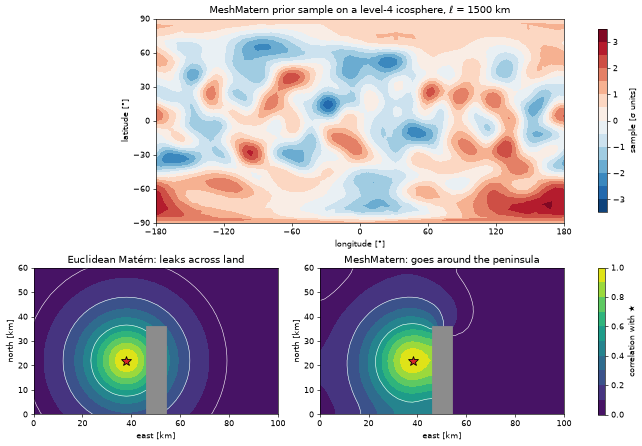

In [23]:
fig, axd = plt.subplot_mosaic(
    [["ico", "ico"], ["eucl", "mesh"]],
    figsize=(11, 7.6),
    height_ratios=[1.25, 1],
    constrained_layout=True,
    dpi=DPI,
)
lim = float(jnp.max(jnp.abs(sample_ico)))
lon_wrap = jnp.concatenate([lon_ico - 360.0, lon_ico, lon_ico + 360.0])
im_i = axd["ico"].tricontourf(
    lon_wrap,
    jnp.tile(lat_ico, 3),
    jnp.tile(sample_ico, 3),
    MaxNLocator(nbins=14, symmetric=True).tick_values(-lim, lim),
    cmap="RdBu_r",
)  # copies at ±360° close the dateline seam
lonlat_axes(
    axd["ico"], "MeshMatern prior sample on a level-4 icosphere, $\\ell$ = 1500 km"
)
fig.colorbar(im_i, ax=axd["ico"], shrink=0.9, label="sample [σ units]")
for ax, corr, title in [
    (axd["eucl"], corr_eucl, "Euclidean Matérn: leaks across land"),
    (axd["mesh"], corr_mesh, "MeshMatern: goes around the peninsula"),
]:
    im = ax.tricontourf(
        P_bay[:, 0], P_bay[:, 1], T_bay, corr, np.linspace(0, 1, 11), cmap="viridis"
    )
    ax.tricontour(
        P_bay[:, 0],
        P_bay[:, 1],
        T_bay,
        corr,
        [0.05, 0.2, 0.5],
        colors="w",
        linewidths=0.7,
    )
    ax.add_patch(plt.Rectangle((46, 0), 8, 36, color="0.55", zorder=3))
    ax.plot(*P_bay[src], "*", color="C3", ms=13, mec="k", zorder=4)
    ax.set_aspect("equal")
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 60)
    ax.set_xlabel("east [km]")
    ax.set_ylabel("north [km]")
    ax.set_title(title)
fig.colorbar(im, ax=[axd["eucl"], axd["mesh"]], shrink=0.9, label="correlation with ★")
plt.show()

**Takeaway:** a triangle mesh is all `MeshMatern` needs; on a coastline it gives the physically right answer (water mixes around land), which no distance-based kernel can.

### 6e. Seasonal cycles with `PeriodicFeatures`

The periodic kernel $k(\tau) = \sigma^2\exp\!\big(-2\sin^2(\pi\tau/p)/\ell^2\big)$ has no spectral density, but it does have an exact Fourier series {cite:p}`solin2014periodic`: with $z = 1/\ell^2$ and $\omega = 2\pi/p$,

$$k(\tau) = q_0 + \sum_{k \ge 1} q_k\cos(k\omega\tau), \qquad q_0 = \sigma^2 e^{-z}I_0(z),\quad q_k = 2\sigma^2 e^{-z}I_k(z),$$

with $I_k$ the modified Bessel functions. `PeriodicFeatures(K)` keeps $2K+1$ features. Physically, $p$ is the forcing period (365.25 days for the seasons, 1 day for the diurnal cycle) and $\ell$ the shape: a large $\ell$ is a near-sinusoidal cycle, a small one allows sharp, asymmetric seasons. Below: four years of daily station temperature with a gap, fitted with $K = 8$ harmonics and forecast one year ahead.

17 features, relative truncation tail 1.4e-07


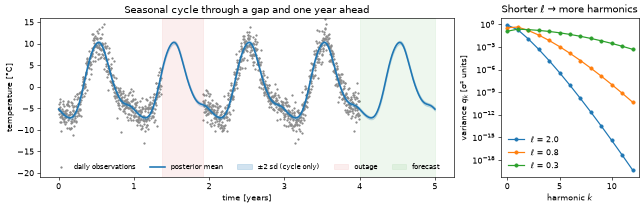

In [24]:
rng = np.random.default_rng(0)
days = np.arange(0.0, 4 * 365.25)
keep = (days < 500) | (days > 700)  # a 200-day instrument outage
t_obs = days[keep]
phase = 2 * np.pi * (t_obs - 200.0) / 365.25
temp = (
    8.0 * np.cos(phase) + 2.5 * np.cos(2 * phase + 0.6) + rng.normal(0, 2.0, t_obs.size)
)
temp_mean = temp.mean()
per = kl.Periodic(lengthscale=0.8, period=365.25, variance=60.0)  # °C², days
T_in = einx.id("n -> n 1", jnp.asarray(t_obs))
pf = kl.PeriodicFeatures(n_harmonics=8).fit(per, T_in)
print(
    f"{2 * 8 + 1} features, relative truncation tail {float(pf.truncation_tail()):.1e}"
)
P_t = pf(T_in)
prec_t = lx.MatrixLinearOperator(
    einx.dot("n f, n g -> f g", P_t, P_t) / 4.0 + jnp.eye(P_t.shape[1]),
    lx.positive_semidefinite_tag,
)
w_t = gx.solve(
    prec_t, einx.dot("n f, n -> f", P_t, jnp.asarray(temp - temp_mean)) / 4.0
)
t_pred = jnp.linspace(0.0, 5 * 365.25, 1500)
P_pred = pf(einx.id("n -> n 1", t_pred))
L_t = gx.cholesky(prec_t).as_matrix()
V_t = jax.scipy.linalg.solve_triangular(L_t, einx.id("n f -> f n", P_pred), lower=True)
sd_t = jnp.sqrt(einx.sum("f n -> n", V_t**2))
mean_t = P_pred @ w_t + temp_mean

fig, axes = plt.subplots(
    1,
    2,
    figsize=(11, 3.5),
    constrained_layout=True,
    dpi=DPI,
    gridspec_kw={"width_ratios": [3, 1]},
)
ax = axes[0]
ax.scatter(t_obs / 365.25, temp, s=3, color="0.55", label="daily observations")
ax.plot(t_pred / 365.25, mean_t, color="C0", lw=2, label="posterior mean")
ax.fill_between(
    t_pred / 365.25,
    mean_t - 2 * sd_t,
    mean_t + 2 * sd_t,
    color="C0",
    alpha=0.2,
    label="±2 sd (cycle only)",
)
ax.axvspan(500 / 365.25, 700 / 365.25, color="C3", alpha=0.08, label="outage")
ax.axvspan(4, 5, color="C2", alpha=0.08, label="forecast")
ax.set_xlabel("time [years]")
ax.set_ylabel("temperature [°C]")
ax.set_title("Seasonal cycle through a gap and one year ahead")
ax.set_ylim(-21, 16)
ax.legend(frameon=False, ncol=5, loc="lower center", fontsize=9)
ax = axes[1]
for j, ell_p in enumerate([2.0, 0.8, 0.3]):
    q = (
        kl.PeriodicFeatures(n_harmonics=12)
        .fit(kl.Periodic(lengthscale=ell_p, period=365.25), T_in)
        .coefficients
    )
    ax.semilogy(
        np.arange(q.shape[0]), q, "o-", color=f"C{j}", ms=4, label=f"$\\ell$ = {ell_p}"
    )
ax.set_xlabel("harmonic $k$")
ax.set_ylabel("variance $q_k$ [σ² units]")
ax.set_title("Shorter $\\ell$ → more harmonics")
ax.legend(frameon=False)
plt.show()

**Takeaway:** `PeriodicFeatures` turns a seasonal (or diurnal) GP into $2K+1$ exact features, so it extrapolates the cycle across gaps and into the future at $O(NK)$ cost.

## Summary

| Question | Answer in kernellib |
|---|---|
| Distance between `(lon, lat)` points | `kl.functional.great_circle_distance` ($R\theta$), `chordal_distance` ($2R\sin\theta/2$) |
| Neighbours, graphs, bandwidths | `metric="great_circle"`, `radius=kl.EARTH_RADIUS_KM` |
| A valid covariance on the sphere | `Chordal(any kernel)`, `GreatCircle*`, `SphereMatern` / `SphereHeat` / `SphereSeries` |
| Nugget, sill, range | `empirical_variogram` → `fit_variogram` |
| Directional correlation | `GeometricAnisotropy`, `LinearTransform` |
| Many points, smooth field | `SphericalHarmonicFeatures` (+ `SlepianFeatures` for a region) |
| Many points, rough field | `tapered_operator` + `gaussx.SparseCholeskySolver` |
| Space–time, transport | `Gneiting`, `Advected`, `RandomAdvectionRBF` |
| Coastlines, irregular domains, networks | `MeshMatern`, `MeshLaplaceFeatures`; `GraphMatern`, `GraphEigenFeatures` |
| Seasonal / diurnal cycles | `PeriodicFeatures` |

See the [Kernels on the Earth guide](../guide/geo.md) for the decision table and the full list of symbols, and the [Geo API reference](xref:api#kernellib.Chordal) for every signature.

In [25]:
print(f"notebook wall time: {time.perf_counter() - NOTEBOOK_START:.0f} s")

notebook wall time: 124 s
